# Introduction to Computer Vision and Convolutional Neural Network

Ig you've been following this series than you already know about regression and classification using `TensorFlow`. In this article, we will learn about `Computer Vision` and `Convolutional Neural Network` (CNN).

**You can find me on**

- [LinkedIn](https://www.linkedin.com/in/pro-programmer/),
- [YouTube](http://www.youtube.com/@itvaya),
- [Gmail](talukderrishat2@gmail.com),
- [discord](https://discord.gg/ZB495XggcF),

**You can find all my articles and code on**

- [Deep Learning With Tensorflow](https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow),

**If you are new to Machine learning, I also have a github for begennier machine learning.**

- [Machine Learning Zero to Hero](https://github.com/RishatTalukder/Machine-Learning-Zero-to-Hero)

**Pre-requisites**

- Python.
- Numpy.
- Pandas.
- Matplotlib/Seaborn.
- Basics of data analysis and preprocessing.
- Basics ML terminologies.
- Basics Tensorflow and keras terminologies.
- Basics of Neural Network.
- [Read the previous article on Multi Class Classification](https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/blob/main/pdfs/5_Multi_Class_Classification.pdf).

**Installations**

We need to install Tensorflow. To do so, we will use the following command:

```bash
    pip install tensorflow
```

or If you have conda installed,
    
```bash
    conda install tensorflow
```


# What is Computer Vision?

It's exactly as it sounds. We make computer see and recognise stuff.

We do that using the power of `Machine learning`.

We can use computer vision for many useful tasks like: Autonomous driving, face recognition, Healthcare, Manufacturing and many more.

But in machine learning lingo these task can be summarised as:

- Image Classification.
- Object detection.
- Segmentation.

And in the core of all of them, we use `Convolutional Neural Network` (CNN).

# Convolutional Neural Network

CNN is not like the typical layered perceptrons model or a normal feedforward network. It uses `convolution` to learn the pattern in the data. And it is a `deep learning model` which is trained using `backpropagation algorithm`.

So, we are changing the recipe.

Let's start with image classification.

## Image Classification

If you've read my previous articles, you already know that we can make a feedForward Neural Network to classify images by flattening the image and then passing it to the Neural Network. But there are some problems.

...But there are some problems.

### The Problem with Flattening

When we pass an image into a traditional feedforward network (or Multi-Layer Perceptron), we have to **flatten** the 2D or 3D grid of pixels into a single, long 1D vector. 

For example, a small color image of $64 \times 64$ pixels has $64 \times 64 \times 3 \text{ (RGB channels)} = 12,288$ individual values. If we flatten it, we run into two massive roadblocks:

1. **Loss of Spatial Relationships:** Images are defined by structure. A pixel's meaning relies entirely on its neighbors. A group of pixels together forms an edge, an edge forms a shape, and shapes form an object. When you flatten an image, you shatter those spatial relationships, forcing the network to look at pixels in isolation.

2. **The Parameter Explosion:** For small images like $16 \times 16$ it is farely okay but for our example of $64 \times 64$, If our first hidden layer has just 50 neurons, that single layer will require over **600 thousand weights** ($12,288 \times 50$). For modern, high-resolution images, the number of parameters quickly spirals out of control, leading to massive memory usage and severe overfitting.

This is why we change the recipe. Enter the **Convolutional Neural Network (CNN)**.


## How CNNs Fix This: The Core Ingredients

Instead of treating an image like a random list of numbers, a CNN treats an image like an actual map. It solves the problems above by using a sequence of specialized layers to automatically extract features without destroying the original shape of the data. 

Here is how a standard CNN architecture builds its "recipe" from start to finish:

```
[Input Image] ➔ [Convolution Layer + ReLU] ➔ [Pooling] ➔ [Flatten] ➔ [Fully Connected Layer] ➔ [Output]
```

### 1. The Convolution Layer (The Feature Finder)

The core building block of a CNN is the **Convolutional Layer**. Instead of connecting every pixel to every single neuron, it uses small matrices called **filters** or **kernels** (typically $3\times3$ or $5\times5$ grids). 

This filter slides (or *convolves*) across the image piece by piece. At each stop, it performs basic matrix multiplication to scan for specific patterns like vertical edges, horizontal lines, or curves. The output of this sliding process is a **Feature Map**, which highlights exactly where those patterns exist in the image.

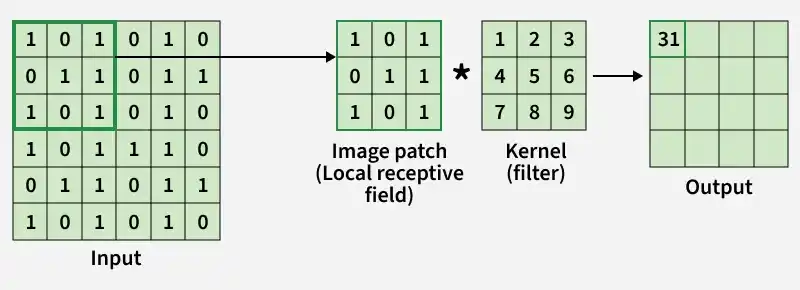

#### The Learnable Parameters

It is crucial to understand that **the numbers inside these filters are the actual weights (parameters) of the network**. In traditional feedforward networks, weights are assigned to individual connections between neurons. Here, the weights live inside the filter matrix. Just like traditional weights, these filter values are initialized randomly and are **gradually optimized by the backpropagation algorithm** using gradient descent as the network learns from its mistakes.

#### How the Operation Works

This filter slides (or *convolves*) across the width and height of the input image piece by piece. At each stop, it performs an element-wise multiplication between the filter's weights and the current chunk of pixel values it is covering, summing up the results into a single value. 

The output of this entire sliding process is a new grid called a **Feature Map**, which highlights exactly where specific patterns exist in the image.

* **Automatic Feature Engineering:** In early computer vision, engineers manually hardcoded these filter values to detect specific things (like a Sobel filter for vertical edges). In a CNN, we don't hardcode anything. The backpropagation algorithm automatically discovers *what* features are important. Early layers might learn filters that detect basic edges, while deeper layers automatically learn filters that look for complex shapes like eyes or tires.

* **Parameter Sharing:** The magic here is that the exact same filter is used to scan the entire image. If a filter learns to detect a horizontal edge, it can find that edge whether it is at the top, bottom, or center of the image. This drastically cuts down the number of parameters the network needs to optimize.


### 2. The Activation Function (Adding Non-Linearity)

Real-world visual data is highly complex and non-linear. The convolution operation described above is entirely linear—it is just repeated multiplication and addition. If we stacked multiple convolutional layers without an activation function, the entire network would mathematically collapse into just one single, giant linear equation, making it incapable of learning intricate patterns.

To prevent this, right after the convolution operation, the network passes the feature maps through a non-linear activation function, most commonly **ReLU (Rectified Linear Unit)**. 

Mathematically, ReLU is incredibly simple: 

$$f(x) = \max(0, x)$$

It leaves any positive value completely unchanged but turns any negative value into a hard zero. 

By clamping negative activations to zero, ReLU introduces non-linearity into the network. This allows the CNN to learn complex, non-linear boundaries and ensures that neurons only fire when they detect a relevant feature, creating a sparse and computationally efficient representation of the image.
Use code with caution.


### 3. The Pooling Layer (The Downsampler)

Images contain a lot of redundant information. A **Pooling Layer** is introduced to reduce the spatial size (width and height) of the feature maps. 

The most common method is **Max Pooling**, where a small window (e.g., $2\times2$) slides across the feature map and keeps only the maximum value from that region. This does two crucial things:

* It shrinks the data size, keeping the network fast and efficient.
* It gives the network **translational invariance**, meaning it can recognize a cat whether it is sitting in the top-left corner or the bottom-right corner of the photo.

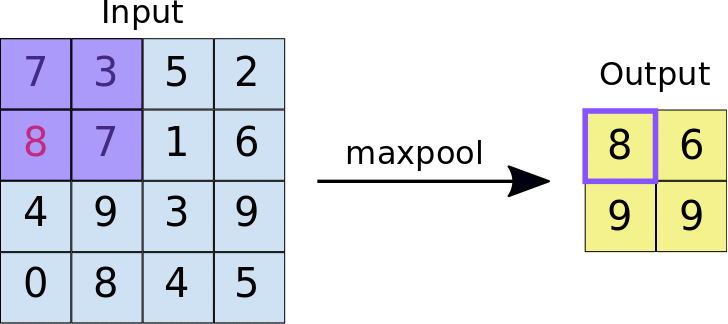

> I like `Average pooling`, the concept is almost exactly the same except instead of taking the maxing of a region it takes average.

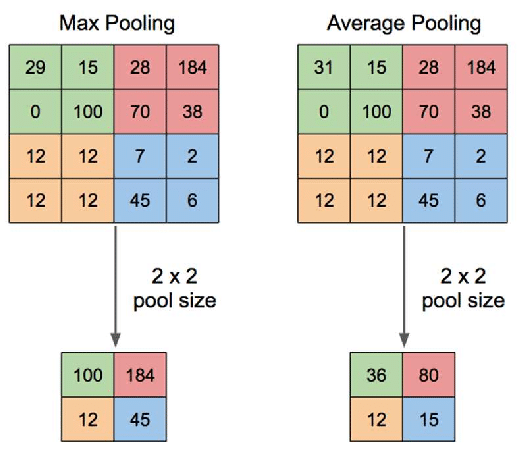

### 4. Fully Connected Layer (The Classifier)

Then we will need a fully connected layer. 

By stacking multiple Convolution and Pooling layers together, the network learns a hierarchy of features: early layers detect simple edges, middle layers detect textures and shapes, and deep layers recognize whole objects (like eyes, noses, or wheels).

Finally, once the features are extracted, the final feature map is **flattened** into a vector. It is then passed to a traditional **Fully Connected (Dense) Layer**. This layer acts as the final judge, looking at all the gathered features to calculate the probability of what the image actually is (e.g., Cat: 92%, Dog: 5%, Car: 3%).

Alright! that covers the main theory behind Convolutional Neural Networks. Now let's get to the actual code.

Let's make a CNN model


# Getting the data

As we are testing out the theory I'll just use a very simple dataset.

you need to install the `tfds` library.

open terminal and type the following commands:
```bash
pip install tfds
```

after that follow the steps below.

In [1]:
import tensorflow as tf;

print(tf.config.list_physical_devices('GPU'))

2026-10-15 16:30:31.305399: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from keras.datasets import fashion_mnist

In [3]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

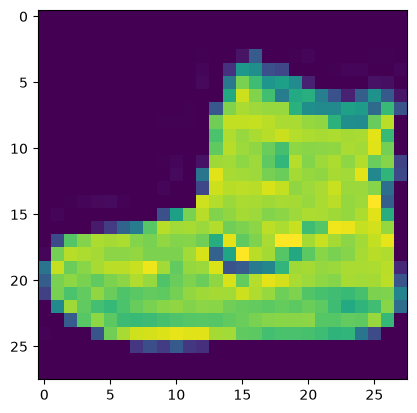

In [4]:
from matplotlib import pyplot as plt

plt.imshow(x_train[0])
plt.show()

The above dataset is called the **Fashion MNIST** dataset. It is a alternative version of the classic MNIST dataset. It contains 10 different classes of clothing items.

Let's see what the classes are.

In [5]:
import numpy as np

np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

So, the classes are already set as `0-9` numeric values but whats the fun in that?

You can find the labels here: https://github.com/zalandoresearch/fashion-mnist#labels

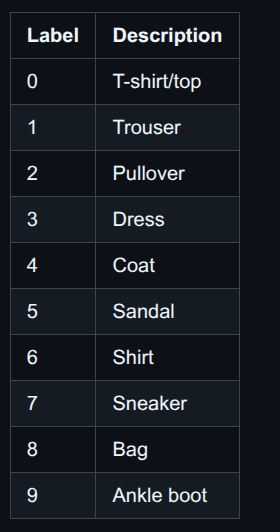

We can save these labels as an array or a dictionary. Either way is fine.

In [6]:
labels = ['T-shirt', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

This will work because if we make a classification model in the output we will get a `probability array`  for each class `0-9` sequentially. So, each index of the probability array will represent the class and the original label also be in the same index.

# Creating the model using TensorFlow

Remember the architecture of a Convolutional Neural Network?

```
Input -> Convolution -> Pooling -> flatten -> Fully Connected -> Output
```

Now let's create the model using TensorFlow.

In [7]:
from keras import layers, models

In [8]:
model = models.Sequential([
    layers.Input((28,28, 1)),
    layers.Conv2D(5, (3,3), activation='relu'),
    layers.AveragePooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(5, activation='relu'),
    layers.Dense(5, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.summary()

I0000 00:00:1792060233.562757   53143 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9724 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:05:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 5)      │            50 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 13, 13, 5)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 845)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │         4,230 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            30 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │            60 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,370 (17.07 KB)

 Trainable params: 4,370 (17.07 KB)

 Non-trainable params: 0 (0.00 B)

> I used `AveragePooling2D` instead of `MaxPooling2D`, because I don't like when data is lost.

Now, we can compile and train the model.

In [9]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

Before training we must normalize the data.

In [10]:
x_train = x_train / 255
x_test = x_test / 255

In [11]:
model.fit(x_train, y_train, epochs=5)

Epoch 1/5


2026-10-15 16:30:34.329389: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 188160000 exceeds 10% of free system memory.
2026-10-15 16:30:34.499718: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 188160000 exceeds 10% of free system memory.
2026-10-15 16:30:35.152560: I external/local_xla/xla/service/service.cc:163] XLA service 0x7ba85800c160 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-15 16:30:35.152574: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3060, Compute Capability 8.6
2026-10-15 16:30:35.170986: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-15 16:30:35.291201: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 90300
2026-10-15 16:30:36.142198: I external/local_xl

 132/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.2095 - loss: 2.1624

I0000 00:00:1792060237.499161   53208 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 985us/step - accuracy: 0.6357 - loss: 0.9753
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 967us/step - accuracy: 0.7874 - loss: 0.5682
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 972us/step - accuracy: 0.8080 - loss: 0.5209
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 968us/step - accuracy: 0.8248 - loss: 0.4861
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 970us/step - accuracy: 0.8365 - loss: 0.4608


We have a fairly modest model. At least it's not less than 50%. 

Now let's break down the model we made.

## Putting It Into Code: A Real-World Example

Let's look at how we build this recipe in code using Keras/TensorFlow. Here is a sequential CNN model designed to take in grayscale images (like the famous MNIST handwritten digit dataset) and classify them into 10 distinct categories:

```python
model = models.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(5, (3, 3), activation='relu'),
    layers.AveragePooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(5, activation='relu'),
    layers.Dense(5, activation='relu'),
    layers.Dense(10, activation='softmax')
])
```

Let's break this down line-by-line to see exactly what is happening to our data at every step:

### 1. `layers.Input((28, 28, 1))`

This defines the entry point for our data. The model expects an input image with a shape of **28 × 28 × 1**. 
* The `28, 28` represents the width and height of the image in pixels.
* The `1` represents the number of color channels. A `1` means it is a grayscale image (if it were a color RGB image, this number would be `3`).

### 2. `layers.Conv2D(5, (3, 3), activation='relu')`

This is where our feature extraction begins! We apply a **2D Convolutional Layer** with the following settings:
* **`5`**: This tells the network to create **5 different filters**. Each filter will learn to look for a unique feature (like horizontal lines, diagonals, or curves).
* **`(3, 3)`**: The spatial size of each filter matrix. It will scan the image in tiny 3 × 3 pixel patches.
* **`activation='relu'`**: As we discussed earlier, immediately after convolving, every negative value in our feature maps is turned to zero to introduce non-linearity.
* *Output shape after this layer:* Since a 3 × 3 filter cannot perfectly center on the very outer edges of a 28 × 28 image without padding, the output size shrinks slightly to **26 × 26 × 5** (5 feature maps, each 26 × 26 pixels).

### 3. `layers.AveragePooling2D((2, 2))`

Next, we downsample the data using an **Average Pooling Layer** instead of the traditional Max Pooling. 
* The **`(2, 2)`** grid slides across our 5 feature maps. Instead of picking only the single highest value, it calculates the **mathematical average** of all four pixel values within that 2 × 2 area.
* While Max Pooling focuses purely on the sharpest, most dominant features (like bright edges), Average Pooling smooths things out by retaining a blend of all the background and feature information in that region.
* This operation cuts the width and height of our feature maps exactly in half.
* *Output shape after this layer:* The dimensions drop from 26 × 26 × 5 down to **13 × 13 × 5**. We have successfully compressed the image data while preserving a smooth, summarized version of its features!

### 4. `layers.Flatten()`

Our spatial feature extraction is complete. Now it is time to pivot to the classification phase. The `Flatten()` layer takes our 3D tensor of feature maps (13 × 13 × 5) and unrolls it into a single, long **1D array**.
* *Math check:* 13 × 13 × 5 = 845. 
* *Output shape after this layer:* A single flat vector containing **845 individual values**, ready to be fed into a standard neural network.

### 5. `layers.Dense(5, activation='relu')`

This is our first **Fully Connected (Dense) Layer**. Every single one of the 845 flattened values is connected to the **5 neurons** in this layer. This layer begins the high-level reasoning, combining the extracted features to look for broader patterns. We use the `'relu'` activation function here again to keep the relationships non-linear.

### 6. `layers.Dense(5, activation='relu')`

Another **Dense Layer** with **5 neurons** and a `'relu'` activation. Stacking dense layers allows the network to learn deeper, more abstract combinations of features before making its final guess.

### 7. `layers.Dense(10, activation='softmax')`

This is the **Output Layer**. Because our goal is to classify the image into 1 of 10 possible classes, this layer has exactly **10 neurons**. 
* Instead of ReLU, we use the **`'softmax'`** activation function here. Softmax takes the raw outputs from the 10 neurons and squashes them into a **probability distribution** between 0 and 1, ensuring all 10 outputs add up to exactly 100%. 
* The neuron with the highest probability value is the model's final prediction (e.g., "There is a 94% chance this image is the number 7").

And now we have a model with fewer parameters but very powerful in pattern recognition.

Well, that's the image classification with `convolutional neural network` for you.

That was just to show you how a convolutional neural network works and how usefull it can be.

Now time to a proper example.

# Loading Real images

Luckily if you need huge ammount image data, there is a fully free image dataset called [Food-101](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/).

> The official [website](https://data.vision.ee.ethz.ch/cvl/datasets_extra/food-101/) contain the whole dataset but I'll not be using all of it. I'm going to modify and keep three food category and images.

I've taken two food classes from the whole dataset made a folder named `cheese_cake_pizza` you can download the dataset urself from my [here](https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/raw/refs/heads/main/4_Convolutional_Neural_network/resource/cheese_cake_pizza.zip).

**You can uncomment the following cell to download and extract the dataset.**

In [ ]:
# !wget "https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/raw/refs/heads/main/4_Convolutional_Neural_network/resource/cheese_cake_pizza.zip"

# import zipfile

# zip_ref = zipfile.ZipFile('cheese_cake_pizza.zip')
# zip_ref.extractall(path='resource')
# zip_ref.close()

--2026-10-15 16:48:31--  https://github.com/RishatTalukder/Deep_Learning_With_Tensorflow/raw/refs/heads/main/4_Convolutional_Neural_network/resource/cheese_cake_pizza.zip
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/RishatTalukder/Deep_Learning_With_Tensorflow/refs/heads/main/4_Convolutional_Neural_network/resource/cheese_cake_pizza.zip [following]
--2026-10-15 16:48:32--  https://raw.githubusercontent.com/RishatTalukder/Deep_Learning_With_Tensorflow/refs/heads/main/4_Convolutional_Neural_network/resource/cheese_cake_pizza.zip
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.108.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 100032201 (95M